# Segmentación cardíaca en resonancia magnética con U-Net

Segmentación multiclase de cortes 2D de resonancia magnética cardíaca (dataset público **ACDC**) usando una U-Net implementada desde cero en PyTorch.

**Contenido**
1. Datos
2. Arquitectura U-Net
3. Modelo, función de pérdida y optimizador
4. Entrenamiento
5. Evaluación: curvas de pérdida, coeficiente DICE por clase y comparación visual

## 1. Datos

Descarga del dataset desde Kaggle.

In [1]:
import kagglehub

# Download latest version
dataset_path = kagglehub.dataset_download("anhoangvo/acdc-dataset")

print("Dataset path:", dataset_path)

print("Path to dataset files:", dataset_path)

Using Colab cache for faster access to the 'acdc-dataset' dataset.
Dataset path: /kaggle/input/acdc-dataset
Path to dataset files: /kaggle/input/acdc-dataset




## Descripción del Conjunto de Datos ACDC

El conjunto de datos [ACDC (Automatic Cardiac Diagnosis Challenge)](https://www.kaggle.com/datasets/anhoangvo/acdc-dataset) es un conjunto de datos de imágenes de resonancia magnética cardíaca (CMR) utilizado para la segmentación automática del ventrículo izquierdo (LV), el miocardio (MYO) y el ventrículo derecho (RV).

En este notebook, estamos trabajando con los **cortes 2D de fin de diástole** preprocesados del conjunto de entrenamiento.

Las clases de segmentación en estos cortes 2D (basado en la convención de etiquetado proporcionada) son:
- Clase 0: Fondo
- Clase 1: Sangre del Ventrículo Derecho (RV blood)
- Clase 2: Miocardio del Ventrículo Izquierdo (LV myocardium)
- Clase 3: Cavidad Sanguínea del Ventrículo Izquierdo (LV blood pool)

Este conjunto de datos es comúnmente utilizado para entrenar y evaluar modelos de segmentación semántica en imágenes médicas.

A continuación se crea un `Dataset` de estos datos

In [2]:
import itertools
import os
import random
import re
from glob import glob
import matplotlib.pyplot as plt
import cv2
import h5py
import numpy as np
import torch
from scipy import ndimage
from scipy.ndimage import zoom
from torch.utils.data import Dataset
from torch.utils.data.sampler import Sampler
from torchvision import transforms
from PIL import Image
import torch.nn.functional as F


from random import sample


class ACDCDataset(Dataset):
    def __init__(self, base_dir=None, transform=None, target_size=(256, 256)):
        self._base_dir = base_dir + "/ACDC_preprocessed/ACDC_training_slices/"


        self.transform = transform
        self.target_size = target_size
        self.num_classes = 4

        self.all_slices = os.listdir(
                self._base_dir)

        # if num is not None and self.split == "train":
        #     self.sample_list = self.sample_list[:num]
        print("total {} samples".format(len(self.all_slices)))

    def __len__(self):
        return len(self.all_slices)

    def __getitem__(self, idx):

        h5f = h5py.File(self._base_dir + self.all_slices[idx], 'r')

        image = h5f['image'][:]
        label = h5f['label'][:]

        # Convert numpy arrays to PIL Images for transformations
        image = Image.fromarray(image)
        label = Image.fromarray(label)


        # Get original dimensions
        original_width, original_height = image.size

        # Calculate the scaling factor
        scale = min(self.target_size[0] / original_height, self.target_size[1] / original_width)

        # Calculate new dimensions after resizing while maintaining aspect ratio
        new_width = int(original_width * scale)
        new_height = int(original_height * scale)

        # Resize the image and label
        image = image.resize((new_width, new_height), Image.BILINEAR) # Use a suitable filter
        label = label.resize((new_width, new_height), Image.NEAREST) # Use nearest for labels

        # Calculate padding
        pad_width = self.target_size[1] - new_width
        pad_height = self.target_size[0] - new_height

        # Apply padding
        padding = (pad_width // 2, pad_height // 2, pad_width - pad_width // 2, pad_height - pad_height // 2)
        image = transforms.functional.pad(image, padding, fill=0) # Pad with 0 for image
        label = transforms.functional.pad(label, padding, fill=0) # Pad with 0 for label (adjust fill value if needed)


        # Convert PIL Images back to tensors
        image = transforms.ToTensor()(image)
        # Convert label to tensor and apply one-hot encoding
        label = torch.tensor(np.array(label), dtype=torch.long)


        sample = {'image': image, 'label': label}

        if self.transform is not None:
            sample = self.transform(sample)
        return sample['image'], sample['label']

In [3]:
acdc_train = ACDCDataset(
    base_dir=dataset_path,
    transform=None, target_size=(200,200))

total 1912 samples


Aquí se muestra una imagen aleatoria con su segmentación superpuesta.

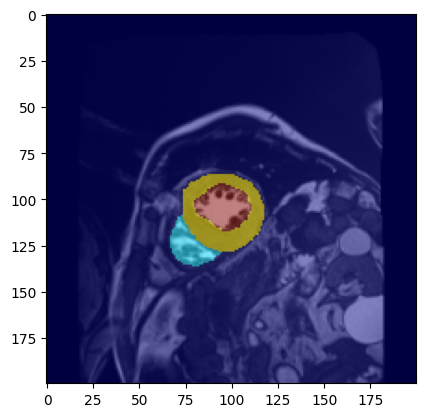

In [4]:
idx = random.randint(0, len(acdc_train) - 1)  # número al azar entre 0 y 1911 (Python cuenta desde 0)
image, label = acdc_train[idx]  # aquí se ejecuta __getitem__: abrir, redimensionar y convertir a tensor

#label_plot = np.argmax(label.numpy(), axis=0)

# Plot the image
plt.imshow(image[0], cmap='gray')  # image[0]: se toma el único canal de [1, 200, 200]


# Overlay the segmentation label with transparency
plt.imshow(label, cmap='jet', alpha=0.5)  # máscara 50% transparente sobre la imagen
plt.show()



**¿Qué se ve en la imagen?**

Es un corte transversal del corazón (eje corto). Cada color corresponde a una clase:

| Color | Clase | Estructura |
|---|---|---|
| Azul oscuro | 0 | Fondo |
| Celeste | 1 | Sangre del ventrículo derecho (RV) |
| Amarillo | 2 | Miocardio del ventrículo izquierdo (MYO), el anillo |
| Rojo | 3 | Sangre del ventrículo izquierdo (LV), dentro del anillo |

Las franjas negras a los lados son el relleno (*padding*) que agrega el `Dataset` para llevar la imagen a 200×200 sin deformarla.

**Resumen hasta aquí**

1. Se descargó el dataset ACDC desde Kaggle (`/kaggle/input/acdc-dataset`).
2. La clase `ACDCDataset` lista los 1912 cortes. Al pedirle uno, lo abre, lo redimensiona a 200×200 manteniendo la proporción (interpolación bilineal para la imagen y *nearest* para la máscara, para no inventar clases intermedias) y entrega la imagen y la máscara como tensores.
3. Se visualizó un ejemplo para comprobar que la imagen y la máscara coinciden.

División del dataset en entrenamiento (80%), validación (10%) y test (10%), con semilla fija para reproducibilidad.

In [5]:
from torch.utils.data import random_split

train_ratio = 0.8
val_ratio = 0.1
test_ratio = 0.1

dataset_size = len(acdc_train)
train_size = int(train_ratio * dataset_size)
val_size = int(val_ratio * dataset_size)
test_size = dataset_size - train_size - val_size


train_dataset, val_dataset, test_dataset = random_split(acdc_train, [train_size, val_size, test_size], torch.Generator().manual_seed(42))


# Print the length of each resulting dataset split
print(f"Length of the training dataset: {len(train_dataset)}")
print(f"Length of the validation dataset: {len(val_dataset)}")
print(f"Length of the testing dataset: {len(test_dataset)}")

Length of the training dataset: 1529
Length of the validation dataset: 191
Length of the testing dataset: 192


In [6]:
from torch.utils.data import DataLoader


batch_size = 32

train_dataloader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataloader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataloader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

# Print the lengths of the DataLoaders (number of batches)
print(f"Number of batches in training dataloader: {len(train_dataloader)}")
print(f"Number of batches in validation dataloader: {len(val_dataloader)}")
print(f"Number of batches in testing dataloader: {len(test_dataloader)}")

Number of batches in training dataloader: 48
Number of batches in validation dataloader: 6
Number of batches in testing dataloader: 6


## 2. Arquitectura U-Net

**Objetivo de la red**

Recibir una imagen del corazón y devolver un mapa con 4 canales, uno por clase, del mismo tamaño 200×200.

- **Entrada:** `[1, 1, 200, 200]` → 1 imagen, 1 canal (escala de grises), 200×200
- **Salida:** `[1, 4, 200, 200]` → 1 imagen, 4 canales, 200×200

Cada canal entrega, para cada pixel, un puntaje de pertenencia a una clase (fondo, RV, MYO, LV). La máscara final se obtiene eligiendo, en cada pixel, el canal con mayor puntaje.

**¿Qué es una U-Net y por qué tiene forma de U?**

```
 ENTRADA 200×200                                 SALIDA 200×200
     │                                                 ▲
  [200×200] ───────── skip connection ───────────► [200×200]
     │ ▼ MaxPool                         ConvT ▲       │
  [100×100] ───────── skip connection ───────────► [100×100]
     │ ▼                                       ▲
   [50×50] ────────── skip connection ───────────►  [50×50]
     │ ▼                                       ▲
   [25×25] ────────── skip connection ───────────►  [25×25]
     │ ▼                                       ▲
   [12×12] ────────────── bottleneck ──────────┘
```

1. **Encoder (bajada):** reduce la imagen a la mitad en cada nivel. Pierde detalle espacial, pero gana contexto: aprende *qué* hay en la imagen.
2. **Decoder (subida):** vuelve a agrandar hasta 200×200, porque se necesita una predicción por pixel: recupera *dónde* está cada estructura.
3. **Skip connections (atajos):** en cada nivel, el decoder concatena las características del encoder del mismo tamaño. Así recupera los bordes finos que se perdieron al reducir. Esto es lo que distingue a la U-Net.

**Detalle por el tamaño 200:** al reducir 4 veces se obtiene 200 → 100 → 50 → 25 → 12 (el pooling redondea hacia abajo). Al subir, 12 × 2 = 24, que no coincide con los 25 del encoder. Por eso el bloque de subida agrega relleno antes de concatenar.

In [7]:
# Bloque 1: DoubleConv, el bloque básico que se repite en todos los niveles de la U-Net

import torch
import torch.nn as nn
import torch.nn.functional as F

class DoubleConv(nn.Module):
    """(Conv 3x3 -> BatchNorm -> ReLU) x 2"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.block(x)

**Bloque `DoubleConv`**

Es el bloque básico que se repite en todos los niveles: aplica dos veces la secuencia Conv → BatchNorm → ReLU.

1. **`nn.Conv2d`**: aplica filtros de 3×3 sobre la imagen para detectar patrones (bordes, curvas, texturas). `in_ch` es el número de canales de entrada y `out_ch` el de salida (cada canal de salida es un detector distinto). `padding=1` mantiene el tamaño espacial (200×200 sigue siendo 200×200).
2. **`nn.BatchNorm2d`**: normaliza las activaciones, lo que hace el entrenamiento más rápido y estable.
3. **`nn.ReLU`**: deja en 0 los valores negativos y mantiene los positivos. Esta no linealidad permite que la red aprenda relaciones complejas.

`forward` simplemente pasa la entrada por esta secuencia.

In [8]:
# Prueba del bloque con una imagen aleatoria de 200×200, para verificar los tamaños

bloque = DoubleConv(in_ch=1, out_ch=32)

imagen_falsa = torch.randn(1, 1, 200, 200)   # una imagen inventada al azar
salida = bloque(imagen_falsa)

print("Entra:", imagen_falsa.shape)
print("Sale: ", salida.shape)


Entra: torch.Size([1, 1, 200, 200])
Sale:  torch.Size([1, 32, 200, 200])


Entra 1 canal y salen 32 canales (32 detectores distintos), sin cambiar el tamaño 200×200. Como la red aún no está entrenada, estos detectores todavía son aleatorios.

In [9]:
# Bloque 2: Down (bajar un nivel en la U-Net)


class Down(nn.Module):
    """MaxPool 2x2 -> DoubleConv"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.pool_conv = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(in_ch, out_ch)
        )

    def forward(self, x):
        return self.pool_conv(x)


**Bloque `Down`**

1. **`nn.MaxPool2d(2)`**: divide la imagen en cuadros de 2×2 y conserva el valor máximo de cada uno, reduciendo el tamaño a la mitad (200 → 100). Se conserva el máximo porque indica dónde un detector se activó con más fuerza.
2. **`DoubleConv`**: busca nuevos patrones sobre la imagen reducida. Como la imagen es más pequeña, el mismo filtro de 3×3 cubre una zona mayor del corazón: en los primeros niveles detecta bordes y en los más profundos formas completas, como el anillo del miocardio.

In [10]:
# Prueba del bloque Down

bajar = Down(in_ch=32, out_ch=64)

entrada = torch.randn(1, 32, 200, 200)   # como lo que salió del bloque anterior
salida = bajar(entrada)

print("Entra:", entrada.shape)
print("Sale: ", salida.shape)


Entra: torch.Size([1, 32, 200, 200])
Sale:  torch.Size([1, 64, 100, 100])


El tamaño baja a la mitad (200 → 100) y los canales se duplican (32 → 64): se pierde resolución espacial, pero se gana información sobre el contenido.

In [11]:
# Bloque 3: Up (subir un nivel en la U-Net)

class Up(nn.Module):
    """ConvTranspose 2x2 -> ajustar tamaño -> concatenar atajo -> DoubleConv"""
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, kernel_size=2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x, skip):
        # 1. Agrandar al doble
        x = self.up(x)

        # 2. Ajustar si los tamaños no calzan (ej: 24 vs 25)
        diff_y = skip.size(2) - x.size(2)
        diff_x = skip.size(3) - x.size(3)
        x = F.pad(x, [diff_x // 2, diff_x - diff_x // 2,
                      diff_y // 2, diff_y - diff_y // 2])

        # 3. Pegar el atajo
        x = torch.cat([skip, x], dim=1)

        # 4. Mirar de nuevo
        return self.conv(x)

**Bloque `Up`**

`forward` recibe dos entradas: `x`, lo que viene del nivel inferior (menor tamaño, más contexto), y `skip`, las características del encoder del mismo nivel (mayor tamaño, más detalle).

1. **`ConvTranspose2d`**: duplica el tamaño espacial (por ejemplo, 25×25 → 50×50) y reduce los canales a la mitad.
2. **Ajuste de tamaño**: si `x` y `skip` no coinciden (24 vs 25), se calcula la diferencia y se rellena con ceros, repartiendo el relleno entre los bordes. Si ya coinciden, la diferencia es 0 y no se modifica nada.
3. **`torch.cat(..., dim=1)`**: concatena `skip` y `x` en la dimensión de los canales. Como el paso 1 redujo los canales a la mitad, la suma vuelve a ser `in_ch`.
4. **`DoubleConv`**: combina el contexto del nivel inferior con el detalle del encoder.

In [12]:
# Prueba del caso difícil: de 12×12 a 25×25


subir = Up(in_ch=512, out_ch=256)

desde_abajo = torch.randn(1, 512, 12, 12)   # el fondo de la U
atajo       = torch.randn(1, 256, 25, 25)   # lo que viene del lado izquierdo

salida = subir(desde_abajo, atajo)

print("Desde abajo:", desde_abajo.shape)
print("Atajo:      ", atajo.shape)
print("Sale:       ", salida.shape)


Desde abajo: torch.Size([1, 512, 12, 12])
Atajo:       torch.Size([1, 256, 25, 25])
Sale:        torch.Size([1, 256, 25, 25])


Se probó el caso más difícil: desde abajo llega un mapa de 12×12 y el atajo mide 25×25. La salida es 25×25, lo que confirma que el ajuste de tamaño funciona.

Con los tres bloques (`DoubleConv`, `Down` y `Up`) se arma la U-Net completa.

In [13]:
# Arquitectura completa: UNet

class UNet(nn.Module):
    def __init__(self, in_channels=1, num_classes=4, base=32):
        super().__init__()
        # Bajada (lado izquierdo de la U)
        self.inc   = DoubleConv(in_channels, base)   # 200x200, 32 capas
        self.down1 = Down(base,     base * 2)        # 100x100, 64 capas
        self.down2 = Down(base * 2, base * 4)        # 50x50,  128 capas
        self.down3 = Down(base * 4, base * 8)        # 25x25,  256 capas
        self.down4 = Down(base * 8, base * 16)       # 12x12,  512 capas (fondo)

        # Subida (lado derecho de la U)
        self.up1   = Up(base * 16, base * 8)         # -> 25x25
        self.up2   = Up(base * 8,  base * 4)         # -> 50x50
        self.up3   = Up(base * 4,  base * 2)         # -> 100x100
        self.up4   = Up(base * 2,  base)             # -> 200x200

        # Salida: 4 capas, una por clase
        self.outc  = nn.Conv2d(base, num_classes, kernel_size=1)

    def forward(self, x):
        # Bajada: guardo cada piso para usarlo como atajo
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        # Subida: uso los atajos guardados
        x = self.up1(x5, x4)
        x = self.up2(x, x3)
        x = self.up3(x, x2)
        x = self.up4(x, x1)

        return self.outc(x)

**Clase `UNet`**

- **`__init__`** define los bloques. `base=32` es el número de canales del primer nivel, y cada nivel hacia abajo los duplica: 32 → 64 → 128 → 256 → 512.
- **`forward`** recorre la U. En la bajada se guarda la salida de cada nivel (`x1` a `x4`) y en la subida se usa cada una como skip connection en orden inverso: `up1` usa `x4`, `up2` usa `x3`, y así sucesivamente.

```
x1 [200×200, 32]  ───────────────────────► up4 ─► [200×200, 32] ─► outc ─► [200×200, 4]
x2 [100×100, 64]  ─────────────────► up3
x3 [50×50, 128]   ───────────► up2
x4 [25×25, 256]   ─────► up1
x5 [12×12, 512]   (bottleneck)
```

- **`outc`** es una convolución de 1×1 que reduce los 32 canales finales a 4, uno por clase. Con kernel 1×1 decide la clase de cada pixel sin mirar a sus vecinos.

La red **no aplica softmax** al final: entrega *logits* (puntajes sin normalizar), porque `CrossEntropyLoss` aplica el softmax internamente.

In [14]:
# Verificación con una imagen real del set de entrenamiento



model = UNet(in_channels=1, num_classes=4)

image, label = train_dataset[0]   # primera imagen del set de entrenamiento
x = image.unsqueeze(0)            # agrego la dimensión del "lote"

print("Imagen sola:", image.shape)
print("Entrada:    ", x.shape)

with torch.no_grad():
    out = model(x)

print("Salida:     ", out.shape)

Imagen sola: torch.Size([1, 200, 200])
Entrada:     torch.Size([1, 1, 200, 200])
Salida:      torch.Size([1, 4, 200, 200])


- **`unsqueeze(0)`** agrega la dimensión del lote (*batch*), porque la red siempre espera un lote de imágenes, aunque sea una sola: `[1, 200, 200]` → `[1, 1, 200, 200]`.
- **`torch.no_grad()`** desactiva el cálculo de gradientes, porque solo se está probando la red, no entrenándola.

La salida tiene la forma pedida, `[1, 4, 200, 200]`. Como la red aún no está entrenada, sus predicciones por ahora son aleatorias.

**Resumen de la arquitectura**

| Bloque | Qué hace |
|---|---|
| `DoubleConv` | Detecta patrones (Conv → BatchNorm → ReLU, dos veces) |
| `Down` | Reduce el tamaño a la mitad y extrae nuevas características |
| `Up` | Duplica el tamaño y concatena la skip connection |
| `UNet` | Une todo: 4 niveles de bajada, 4 de subida y una capa de salida con 4 clases |

## 3. Modelo, función de pérdida y optimizador

Para entrenar se necesitan tres elementos:

| Elemento | Rol |
|---|---|
| Modelo | La red que hace las predicciones |
| Función de pérdida | Mide qué tan equivocadas están las predicciones |
| Optimizador | Ajusta los pesos de la red para reducir la pérdida |

In [15]:
# Uso de GPU si está disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Usando:", device)

# 1. El modelo
model = UNet(in_channels=1, num_classes=4, base=32).to(device)

# 2. La función de pérdida
criterion = nn.CrossEntropyLoss()

# 3. El optimizador
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)



Usando: cuda


**1. Modelo.** Se crea una U-Net nueva (sin entrenar) y se envía a la GPU con `.to(device)`.

**2. Función de pérdida: `CrossEntropyLoss`.** Para cada pixel compara la predicción con la clase real de la máscara. Penaliza poco cuando la red acierta con seguridad y mucho cuando se equivoca con seguridad. El resultado es el promedio sobre todos los pixeles.

Es la elección estándar para segmentación multiclase, donde cada pixel pertenece a una sola clase (fondo, RV, MYO o LV). Aplica softmax internamente, por eso la red entrega logits. Una alternativa válida es la **Dice Loss**, que optimiza directamente la superposición entre la máscara predicha y la real; también es común combinar ambas.

**3. Optimizador: Adam.** Actualiza los parámetros de la red (`model.parameters()`) a partir de los gradientes. La tasa de aprendizaje `lr = 1e-3` controla el tamaño de cada paso: si es muy grande el entrenamiento se vuelve inestable, y si es muy pequeña aprende muy lento. 0,001 es un valor de partida habitual para Adam.

## 4. Entrenamiento

**Loop de entrenamiento**

- **Época:** una pasada completa por las 1529 imágenes de entrenamiento (48 batches).
- En cada época el modelo entrena con el set de entrenamiento y luego se evalúa en el set de validación.

In [16]:
# Funciones de entrenamiento y validación

import copy

def train_one_epoch(model, dataloader, criterion, optimizer, device):
    model.train()                       # modo "estudiar"
    total_loss = 0.0

    for images, labels in dataloader:   # bandeja por bandeja
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()           # 1. borrar correcciones anteriores
        outputs = model(images)         # 2. la red responde
        loss = criterion(outputs, labels)  # 3. el profesor corrige
        loss.backward()                 # 4. ver qué causó el error
        optimizer.step()                # 5. ajustar para mejorar

        total_loss += loss.item()

    return total_loss / len(dataloader)  # error promedio de la vuelta


def validate(model, dataloader, criterion, device):
    model.eval()                        # modo "prueba"
    total_loss = 0.0

    with torch.no_grad():               # no se aprende, solo se mide
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            total_loss += loss.item()

    return total_loss / len(dataloader)

**`train_one_epoch`**

- `model.train()` activa el modo entrenamiento (BatchNorm se comporta distinto al entrenar y al evaluar).
- Se recorren los batches y se envían a la GPU con `.to(device)`.

Para cada batch:

| Paso | Código | Qué hace |
|---|---|---|
| 1 | `optimizer.zero_grad()` | Borra los gradientes del batch anterior |
| 2 | `model(images)` | La red hace sus predicciones |
| 3 | `criterion(outputs, labels)` | Calcula la pérdida |
| 4 | `loss.backward()` | Backpropagation: calcula cuánto contribuyó cada parámetro al error |
| 5 | `optimizer.step()` | Actualiza los parámetros para reducir el error |

Se devuelve la pérdida promedio de la época.

**`validate`**

Igual que la anterior, pero sin los pasos 1, 4 y 5: solo se predice y se mide. Usa `model.eval()` y `torch.no_grad()` (no se calculan gradientes, lo que ahorra memoria). Sirve para comprobar si el modelo generaliza a imágenes que no usó para entrenar, y así detectar overfitting.

**Loop principal (celda siguiente).** Se entrena durante 30 épocas y se guardan las pérdidas de entrenamiento y validación para graficarlas. Cada vez que la pérdida de validación mejora, se guarda una copia de los pesos; al final se carga la mejor versión del modelo.

In [17]:
# Entrenamiento del modelo


num_epochs = 30

train_losses = []   # aquí anoto el error de cada vuelta (estudio)
val_losses = []     # aquí anoto el error de cada vuelta (ensayo)

best_val_loss = float('inf')
best_model_weights = None

for epoch in range(num_epochs):
    train_loss = train_one_epoch(model, train_dataloader, criterion, optimizer, device)
    val_loss = validate(model, val_dataloader, criterion, device)

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    # Si es el mejor ensayo hasta ahora, guardo una copia del modelo
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        marca = "  (mejor hasta ahora)"
    else:
        marca = ""

    print(f"Época {epoch+1:2d}/{num_epochs} | Train loss: {train_loss:.4f} | Val loss: {val_loss:.4f}{marca}")

# Al final, me quedo con la mejor versión
model.load_state_dict(best_model_weights)
print("\n¡Listo! Mejor val loss:", round(best_val_loss, 4))


Época  1/30 | Train loss: 0.7011 | Val loss: 0.4431  (mejor hasta ahora)
Época  2/30 | Train loss: 0.2698 | Val loss: 0.1839  (mejor hasta ahora)
Época  3/30 | Train loss: 0.1328 | Val loss: 0.1043  (mejor hasta ahora)
Época  4/30 | Train loss: 0.0785 | Val loss: 0.0730  (mejor hasta ahora)
Época  5/30 | Train loss: 0.0543 | Val loss: 0.0465  (mejor hasta ahora)
Época  6/30 | Train loss: 0.0392 | Val loss: 0.0354  (mejor hasta ahora)
Época  7/30 | Train loss: 0.0306 | Val loss: 0.0352  (mejor hasta ahora)
Época  8/30 | Train loss: 0.0259 | Val loss: 0.0272  (mejor hasta ahora)
Época  9/30 | Train loss: 0.0230 | Val loss: 0.0252  (mejor hasta ahora)
Época 10/30 | Train loss: 0.0194 | Val loss: 0.0200  (mejor hasta ahora)
Época 11/30 | Train loss: 0.0176 | Val loss: 0.0324
Época 12/30 | Train loss: 0.0158 | Val loss: 0.0183  (mejor hasta ahora)
Época 13/30 | Train loss: 0.0141 | Val loss: 0.0215
Época 14/30 | Train loss: 0.0136 | Val loss: 0.0187
Época 15/30 | Train loss: 0.0137 | Val lo

**Análisis del entrenamiento**

- **Épocas 1–10:** la pérdida baja rápidamente (de 0,70 a 0,02).
- **Épocas 11–23:** sigue bajando más lento, con pequeñas oscilaciones en validación (épocas 11, 13 y 19).
- **Épocas 23–28:** la pérdida de validación se estabiliza cerca de 0,0106.
- **Épocas 29–30:** suben ambas pérdidas (ver análisis en la sección 5).

El mejor modelo corresponde a la **época 23** (val loss = 0,0106), y es el que se usa en la evaluación.

## 5. Evaluación

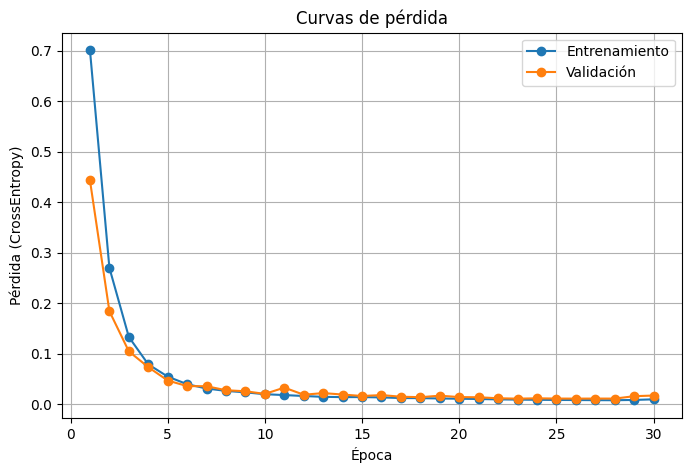

In [19]:
# 5.1 Curvas de pérdida

epochs = range(1, len(train_losses) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, train_losses, 'o-', label='Entrenamiento')
plt.plot(epochs, val_losses, 'o-', label='Validación')
plt.xlabel('Época')
plt.ylabel('Pérdida (CrossEntropy)')
plt.title('Curvas de pérdida')
plt.legend()
plt.grid(True)
plt.show()

**¿Existe overfitting?**

No se observa overfitting significativo. Las curvas de entrenamiento y validación disminuyen juntas durante todo el entrenamiento y la brecha entre ambas es pequeña (0,0086 vs 0,0106 en la época 23, la del mejor modelo). La pérdida de validación se estabiliza alrededor de la época 23, pero no aumenta de forma sostenida mientras la de entrenamiento baja, que sería la señal típica de overfitting.

El aumento en las épocas 29–30 ocurre en **ambas** curvas, por lo que se atribuye a inestabilidad del optimizador (learning rate alto para la etapa final) y no a sobreajuste. Se conservó el modelo de la época con menor pérdida de validación (época 23).

**Observación sobre la época 1:** la pérdida de validación (0,44) es menor que la de entrenamiento (0,70). Esto se debe a que la pérdida de entrenamiento es el promedio de toda la época, incluyendo los primeros batches, cuando el modelo aún no había aprendido nada, mientras que la validación se mide al final de la época, con el modelo ya mejorado.

In [20]:
# 5.2 Coeficiente DICE por clase
# DICE = 2|P ∩ G| / (|P| + |G|)  →  1 = coincidencia perfecta, 0 = sin superposición

def dice_por_clase(model, dataloader, device, num_classes=4):
    model.eval()
    interseccion = torch.zeros(num_classes)
    suma_real = torch.zeros(num_classes)
    suma_pred = torch.zeros(num_classes)

    with torch.no_grad():
        for images, labels in dataloader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)              # [B, 4, 200, 200] puntajes
            preds = outputs.argmax(dim=1)        # [B, 200, 200] clase elegida

            for c in range(num_classes):
                pred_c = (preds == c)
                real_c = (labels == c)
                interseccion[c] += (pred_c & real_c).sum().item()
                suma_pred[c]    += pred_c.sum().item()
                suma_real[c]    += real_c.sum().item()

    dice = 2 * interseccion / (suma_real + suma_pred)
    return dice


nombres = ["Fondo", "RV (sangre derecha)", "MYO (músculo izq.)", "LV (sangre izq.)"]

dice_test = dice_por_clase(model, test_dataloader, device)

print("Coeficiente DICE en el TEST set:\n")
for nombre, d in zip(nombres, dice_test):
    print(f"  {nombre:22s}: {d:.4f}")
print(f"\n  Promedio clases del corazón (1-3): {dice_test[1:].mean():.4f}")

Coeficiente DICE en el TEST set:

  Fondo                 : 0.9987
  RV (sangre derecha)   : 0.9129
  MYO (músculo izq.)    : 0.8834
  LV (sangre izq.)      : 0.9543

  Promedio clases del corazón (1-3): 0.9169


**Cálculo del DICE**

$$\text{DICE} = \frac{2\,|P \cap G|}{|P| + |G|}$$

donde $P$ son los pixeles predichos de una clase y $G$ los pixeles reales de esa clase. DICE = 1 indica coincidencia perfecta y DICE = 0, ninguna superposición.

- `outputs.argmax(dim=1)` convierte los 4 canales en una sola máscara, eligiendo la clase con mayor puntaje en cada pixel.
- Para cada clase se cuentan los pixeles predichos, los reales y la intersección (`pred_c & real_c`), acumulando sobre todas las imágenes.
- Se evalúa sobre el **test set** (192 imágenes que el modelo no vio ni en entrenamiento ni en validación).

A diferencia de la pérdida promedio, que está dominada por el fondo, el DICE por clase muestra el desempeño en cada estructura del corazón por separado.

**Resultados del DICE (test set)**

| Clase | DICE | ¿Supera 0,85? |
|---|---|---|
| Fondo | 0,9987 | Sí |
| RV (sangre ventrículo derecho) | 0,9129 | Sí |
| MYO (miocardio) | 0,8834 | Sí |
| LV (sangre ventrículo izquierdo) | 0,9543 | Sí |

Todas las clases superan el umbral de 0,85.

- **Fondo:** ocupa casi toda la imagen, por lo que es la clase más fácil.
- **LV:** es la mejor de las estructuras cardíacas; es una región redondeada, de alto contraste y bien delimitada por el miocardio.
- **RV:** tiene forma de media luna irregular, que varía bastante entre cortes.
- **MYO:** es la más difícil. Es una estructura delgada en forma de anillo con dos bordes (interno y externo), por lo que pequeños errores en los contornos representan una fracción grande de su área total.

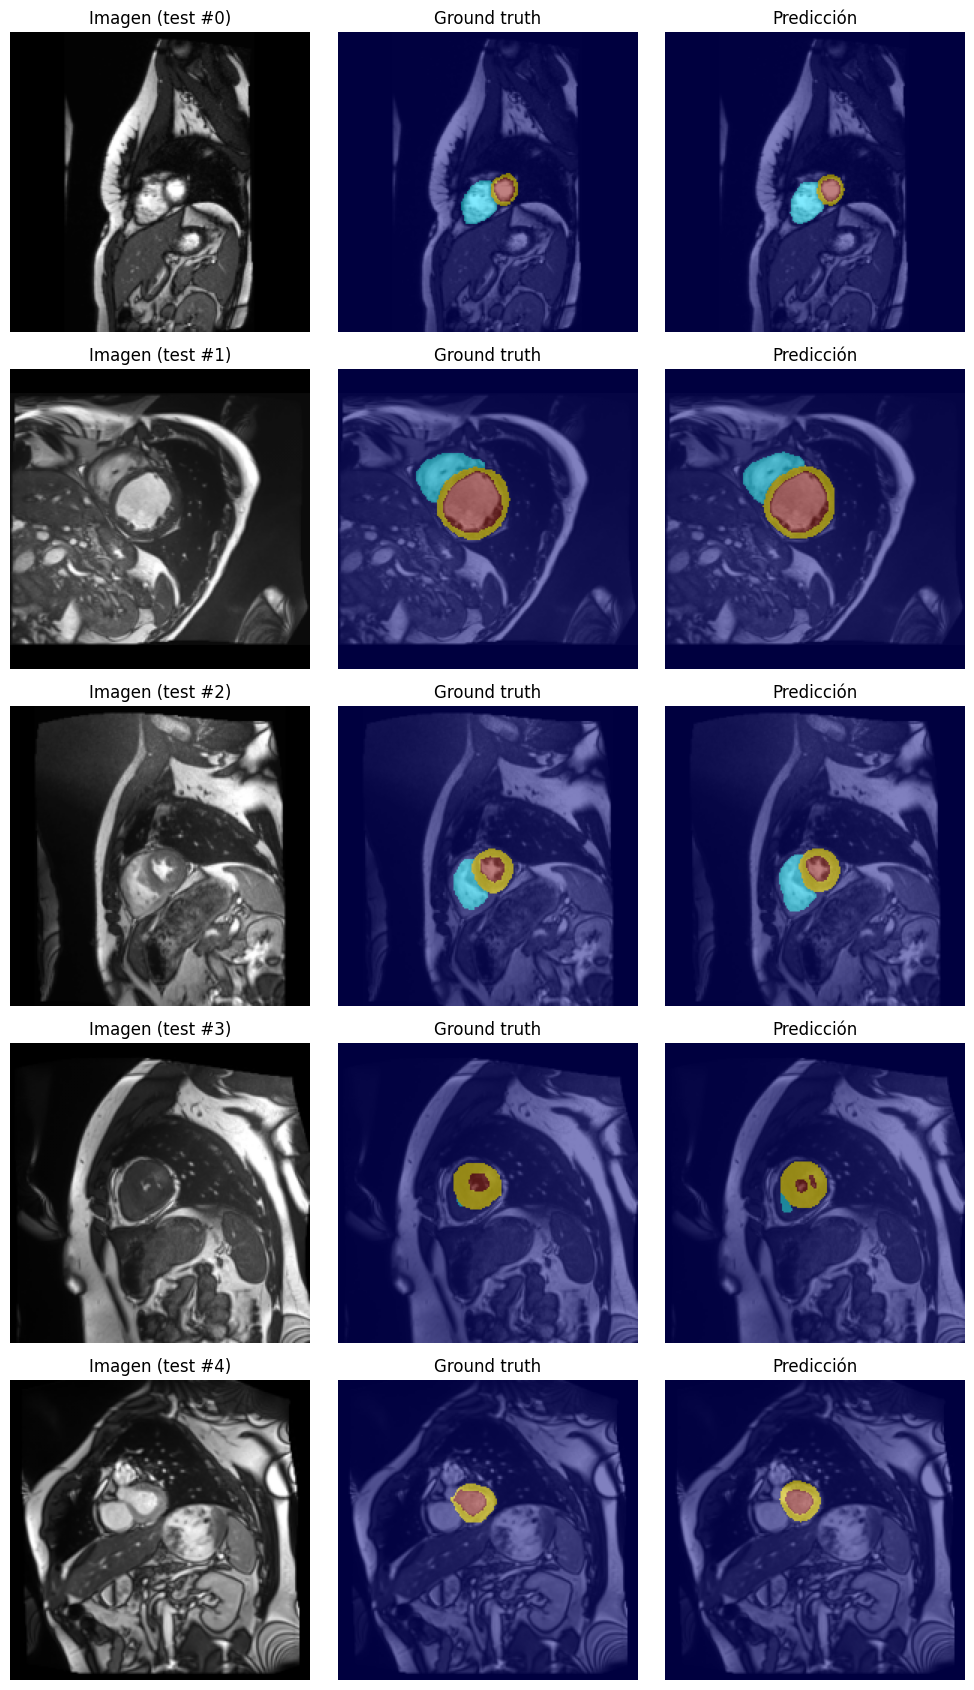

In [22]:
# 5.3 Comparación visual de 5 imágenes del test set

model.eval()

# Elijo las primeras 5 imágenes del test que tengan corazón
indices = []
for i in range(len(test_dataset)):
    _, lbl = test_dataset[i]
    if lbl.max() > 0:
        indices.append(i)
    if len(indices) == 5:
        break

fig, axes = plt.subplots(5, 3, figsize=(10, 17))

for fila, idx in enumerate(indices):
    image, label = test_dataset[idx]

    with torch.no_grad():
        output = model(image.unsqueeze(0).to(device))
        pred = output.argmax(dim=1).squeeze(0).cpu()

    axes[fila, 0].imshow(image[0], cmap='gray')
    axes[fila, 0].set_title(f"Imagen (test #{idx})")

    axes[fila, 1].imshow(image[0], cmap='gray')
    axes[fila, 1].imshow(label, cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[fila, 1].set_title("Ground truth")

    axes[fila, 2].imshow(image[0], cmap='gray')
    axes[fila, 2].imshow(pred, cmap='jet', alpha=0.5, vmin=0, vmax=3)
    axes[fila, 2].set_title("Predicción")

    for col in range(3):
        axes[fila, col].axis('off')

plt.tight_layout()
plt.show()

**Visualización**

- Se eligen las primeras 5 imágenes del test set que contienen corazón (`lbl.max() > 0`).
- Se muestra una grilla de 5×3: la imagen original, el ground truth superpuesto y la predicción superpuesta.
- Para predecir: `unsqueeze(0)` agrega la dimensión del batch, `.to(device)` envía la imagen a la GPU, `argmax(dim=1)` elige la clase por pixel, `squeeze(0)` quita la dimensión del batch y `.cpu()` devuelve el resultado a la CPU para graficarlo.
- `vmin=0, vmax=3` fija la escala de colores, para que el mismo color represente la misma clase en todas las imágenes.

**Comparación visual**

En las 5 imágenes del test set, las máscaras predichas coinciden en gran medida con el ground truth, en corazones de distintos tamaños y orientaciones. En las imágenes #0, #1, #2 y #4 las diferencias se limitan a pequeñas variaciones en los bordes; además, en la #4 el modelo no predice ventrículo derecho, de forma correcta, ya que el ground truth tampoco lo contiene.

El caso más difícil es la imagen #3, que tiene un miocardio grueso y una cavidad del ventrículo izquierdo muy pequeña (probablemente un corte cercano al ápice). Ahí el modelo fragmenta la cavidad en dos regiones y sobreestima levemente el ventrículo derecho. Esto es coherente con que el miocardio sea la clase con menor DICE (0,8834): los errores se concentran en estructuras pequeñas o delgadas, donde unos pocos pixeles mal clasificados pesan mucho en la métrica.

## 6. Hiperparámetros y trabajo futuro

Con la configuración inicial todas las clases superan un DICE de 0,85 en el test set (RV 0,9129 · MYO 0,8834 · LV 0,9543).

**Hiperparámetros usados:**

| Hiperparámetro | Valor |
|---|---|
| Arquitectura | U-Net de 4 niveles, 32 filtros base, BatchNorm |
| Función de pérdida | CrossEntropyLoss |
| Optimizador | Adam, lr = 1×10⁻³ |
| Batch size | 32 |
| Épocas | 30 (se conserva el modelo con menor pérdida de validación, época 23) |

**Posibles mejoras** para subir el DICE del miocardio (la clase más cercana al umbral):
1. Reducir el learning rate en las últimas épocas con un *scheduler*, ya que en las épocas 29–30 se observó inestabilidad.
2. Combinar CrossEntropy con Dice Loss, que optimiza directamente la superposición y favorece las estructuras delgadas.
3. Aumentar los filtros base de 32 a 64.